# S4, part 2 · EfficientNet
## Goal
Connect MobileNetV2 blocks to EfficientNet; explain channel gating, compound scaling, and the V2 training-speed motivation. **19–20 October 2026: MobileNet + EfficientNet in the same session.**

## Setup
CPU, synthetic data, no downloads. Read saved outputs on GitHub, or use Colab / the course `dl-2026` kernel. Saved outputs are ready to project. [Paper navigation](04_Papers.md) includes direct PDF links.


In [1]:
from pathlib import Path
import platform
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision.models import efficientnet_b0
from IPython.display import display, Markdown
torch.manual_seed(42)
torch.set_num_threads(1)
FIG=Path('figures'); FIG.mkdir(exist_ok=True)
plt.rcParams.update({'font.size':13,'figure.dpi':120})
print(f'Python {platform.python_version()} | PyTorch {torch.__version__} | CPU')

Python 3.13.5 | PyTorch 2.14.1 | CPU


## Steps
### 1 · Three knobs, one compute budget
Depth = more repeated blocks; width = more channels; resolution = larger feature maps. For a simplified convolution-dominated model, relative compute is approximately **d × w² × r²**. This is an arithmetic model, not measured accuracy or latency.

Predict the cost when all three dimensions grow by 20%. Why is it not just 1.2×?

[EfficientNet PDF, Figure 2, page 2](https://arxiv.org/pdf/1905.11946v5#page=2).


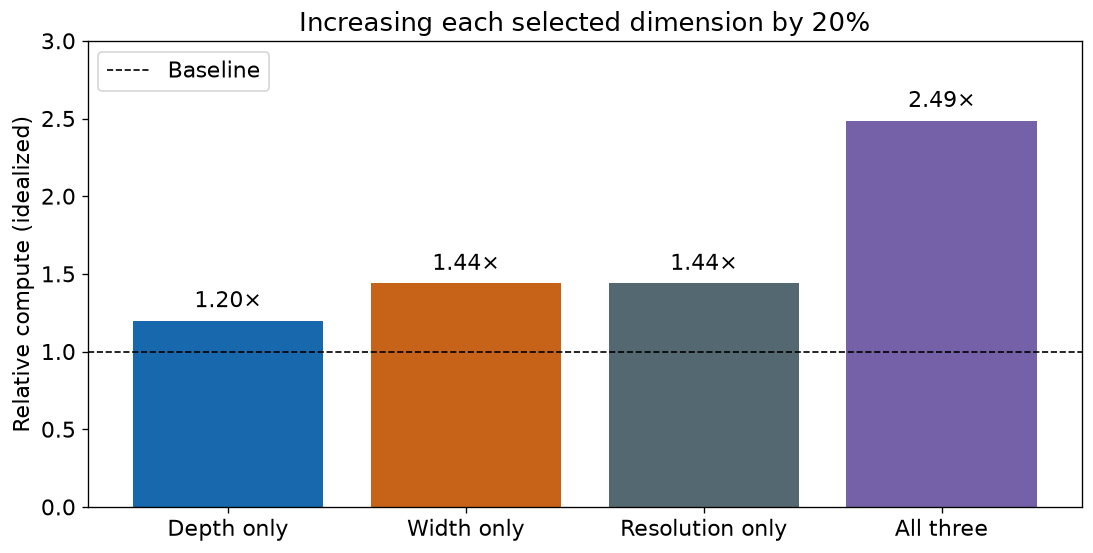

In [2]:
labels=['Depth only','Width only','Resolution only','All three']
factors=np.array([1.2,1.2**2,1.2**2,1.2**5])
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
bars=ax.bar(labels,factors,color=['#1768ac','#c76319','#536871','#7561a8'])
ax.axhline(1,color='black',linestyle='--',linewidth=1,label='Baseline')
ax.bar_label(bars,labels=[f'{v:.2f}×' for v in factors],padding=5)
ax.set(ylabel='Relative compute (idealized)',ylim=(0,3),title='Increasing each selected dimension by 20%')
ax.legend();fig.savefig(FIG/'04_scaling_budget.png');plt.show()
assert np.isclose(factors[-1],2.48832)

### 2 · Compound scaling
Choose coefficients once, then use one budget knob φ:

`d = α^φ`, `w = β^φ`, `r = γ^φ`, with `α β² γ² ≈ 2`.

The paper uses α=1.2, β=1.1, γ=1.15. Channel/repeat rounding and implementation choices matter; do not read this table as an exact B0–B7 specification. Here **α means depth scaling**; in the preceding MobileNet notebook α meant width.

[Paper: equation 3, page 4](https://arxiv.org/pdf/1905.11946v5#page=4), [B0 architecture and coefficients, page 5](https://arxiv.org/pdf/1905.11946v5#page=5).

**Exercise (3 minutes):** at φ=1, calculate d,w,r and relative compute. At φ=2, must accuracy double? Does image resolution directly change convolution parameter count?


In [3]:
alpha,beta,gamma=1.2,1.1,1.15
rows=[]
for phi in range(4):
    d,w,r=alpha**phi,beta**phi,gamma**phi
    rows.append(f'| {phi} | {d:.3f} | {w:.3f} | {r:.3f} | {d*w*w*r*r:.3f}× |')
display(Markdown('| φ | Depth | Width | Resolution | Approx. compute |\n|---|---|---|---|---|\n'+'\n'.join(rows)))
assert np.isclose(alpha*beta**2*gamma**2,1.92027)

| φ | Depth | Width | Resolution | Approx. compute |
|---|---|---|---|---|
| 0 | 1.000 | 1.000 | 1.000 | 1.000× |
| 1 | 1.200 | 1.100 | 1.150 | 1.920× |
| 2 | 1.440 | 1.210 | 1.322 | 3.687× |
| 3 | 1.728 | 1.331 | 1.521 | 7.081× |

### 3 · Squeeze-and-Excitation: a volume control per channel
Pool each channel over H×W → use a small learned network → sigmoid gates → multiply the original map by its gate. Every spatial position within one channel receives the same gate for that sample. Gates depend on the input; they do not need to sum to 1.

[SE paper PDF](https://arxiv.org/pdf/1709.01507). The following is a simplified generic SE block; reduction is based on its own input width, not an exact reproduction of EfficientNet's squeeze-channel convention.


In [4]:
class DemoSE(nn.Module):
    def __init__(self,channels,reduction=4):
        super().__init__()
        hidden=max(1,channels//reduction)
        self.gate=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Conv2d(channels,hidden,1),
                                nn.ReLU(),nn.Conv2d(hidden,channels,1),nn.Sigmoid())
    def forward(self,x): return x*self.gate(x)
x=torch.randn(2,8,7,7)
se=DemoSE(8).eval()
with torch.inference_mode():
    gates=se.gate(x); y=se(x)
assert gates.shape==(2,8,1,1) and y.shape==x.shape
assert bool(((gates>0)&(gates<1)).all())
torch.testing.assert_close(y,x*gates)
print('Input:',tuple(x.shape),' Gates:',tuple(gates.shape),' Output:',tuple(y.shape))
print('Random, untrained gates for sample 0:',gates[0,:,0,0].numpy().round(3))

Input: (2, 8, 7, 7)  Gates: (2, 8, 1, 1)  Output: (2, 8, 7, 7)
Random, untrained gates for sample 0: [0.482 0.586 0.609 0.624 0.41  0.433 0.438 0.547]


### 4 · Inspect B0
EfficientNet's baseline combines MBConv with SE and a scaling strategy. MobileNetV2 and EfficientNet are related, but are not identical architectures. In this implementation, inspect SiLU/Swish, SE, linear projection and stochastic depth.

[Architecture: Table 1, page 5](https://arxiv.org/pdf/1905.11946v5#page=5). Its resolution column describes stage inputs. Trace the stride before claiming the output size.


In [5]:
model=efficientnet_b0(weights=None).eval()
with torch.inference_mode(): logits=model(torch.zeros(1,3,224,224))
print('Untrained B0 output:',tuple(logits.shape))
print('Parameters:',format(sum(p.numel() for p in model.parameters()),','))
print('One MBConv block:')
print(model.features[2][0])
assert logits.shape==(1,1000)
assert sum(p.numel() for p in model.parameters())==5288548

Untrained B0 output: (1, 1000)
Parameters: 5,288,548
One MBConv block:
MBConv(
  (block): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Conv2dNormActivation(
      (0): Conv2d(96, 96, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=96, bias=False)
      (1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (2): SqueezeExcitation(
      (avgpool): AdaptiveAvgPool2d(output_size=1)
      (fc1): Conv2d(96, 4, kernel_size=(1, 1), stride=(1, 1))
      (fc2): Conv2d(4, 96, kernel_size=(1, 1), stride=(1, 1))
      (activation): SiLU(inplace=True)
      (scale_activation): Sigmoid()
    )
    (3): Conv2dNormActivation(
      (0): Conv2d(96, 24, kernel_size=(1, 1), stride=(1, 1), bias=False)


### 5 · EfficientNetV2: fewer operations is not the only goal
Fused-MBConv replaces expansion 1×1 + depthwise 3×3 with a standard 3×3 expansion. Early fused blocks can improve hardware utilization despite more arithmetic. V2 also uses progressive learning: increase image size during training while adjusting regularization.

Open [V2 Figure 2 and Table 3, page 3](https://arxiv.org/pdf/2104.00298v3#page=3). Compare both throughput columns and FLOPs; do not generalize one accelerator result to every device. These are **EfficientNetV2** changes, not the original EfficientNet scaling paper.

## Checks
1. Why does width usually enter the cost twice?
2. Does an SE gate have a separate value for every pixel?
3. Why might a fused block with more FLOPs train faster?
4. Is compound scaling a guarantee that accuracy improves by a fixed percentage?

## Next Steps
Next seminar: Object Detection / YOLOv1. S6 is reserved for RL or SSL, topic still undecided. No new graded assignment.

All relevant primary links and optional background papers: [04_Papers.md](04_Papers.md).
